# Solving the durable model with a utility cost of adjusting

Infinite-horizon steady states and sequence-space Jacobians with respect to `Rfree` and `labor`.
Search and prices are off. Taste shocks are the Zorzi–Beraja logit: scale `sigma_eps` and a utility cost `kappa` subtracted from the adjuster value.

Baseline: $\sigma_\zeta = 0.15$, $\kappa = 0.5$.

1. Vary the taste scale at fixed $\kappa = 0.5$: $\sigma_\zeta \in \{0.1, 0.15, 0.2\}$.
2. Vary the utility cost at fixed $\sigma_\zeta = 0.1$: $\kappa \in \{0.25, 0.5, 0.75\}$.

The baseline pair is solved once and reused in both sweeps.

Saves results to `Output/DurableModel_Taste_kappa_Inf_SS.pkl`,
`Output/DurableModel_Taste_kappa_Inf_Jacobians_Rfree.pkl`, and
`Output/DurableModel_Taste_kappa_Inf_Jacobians_labor.pkl`.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import copy
import time
import datetime
import pickle
from pathlib import Path

import pandas as pd
from IPython.display import display

start_time = time.time()

from DurableModel_Fast import DurableConsumer

FIG_DIR = Path("../Figures/DurableModel")
FIG_DIR.mkdir(parents=True, exist_ok=True)

OUT_DIR = Path("../Output")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Middle value of each three-point sweep is the baseline (red solid).
LINE_STYLES = [
    ("k", "-"),
    ("r", "-"),
    ("k", "--"),
]

SS_KEYS = ["C", "D", "DEX", "TEX", "A", "ADJ"]
JAC_KEYS = ["C", "DEX", "TEX", "D", "A", "ADJ"]


In [2]:
### Baseline parameters for all models

durable_defaults = dict(
    CRRA=2.0,
    DiscFac=0.975,
    LivPrb=1.0,
    alpha=0.75,
    d_ubar=1e-4,
    dDepr=0.05,
    adjC=0.10,
    MaintCost=0.0,
    OpCost=0.0,
    Rfree=1.04**(0.25),
    RSpread=0.0,
    PermGroFac=1.0,
    LTV=0.0,
    BoroCnstArt=0.0,
    # Income
    PermShkStd=0.0,
    PermShkCount=1,
    TranShkStd=0.2,
    TranShkCount=7,
    UnempPrb=0.0,
    IncUnemp=0.0,
    IncUnemp_Std=0.1,
    truncation=2,
    taxrate=0.0,
    labor=1.0,
    wage=1.0,
    # Channels. sigma_eps is the EV scale; kappa is the utility cost of adjusting.
    sigma_eps=0.0,
    kappa=0.0,
    SearchCost=0.1,
    ScaleBool=False,
    e_grid_count=101,
    PriceShkCount=5,
    PriceShkStd=0.1,
    # EoP method
    use_expected=True,
    use_TransitionMatrix=False,
    # Grids
    nNrmMax=10, #5.0,
    nNrmCount=200,
    mNrmMax=16.0, #8.0,
    mNrmCount=200,
    xNrmMax=26, #13.0,
    xNrmCount=100,
    aNrmMax=16.0, #8.0,
    aNrmCount=200,
    NestFac=1,
    grid_type="exp_mult",
    TranMatrix_mCount=1010,
    TranMatrix_bCount=1000,
    N_scan=800,
    cycles=0,
    T_cycle=1,       # number of periods before terminal when cycles >= 1
    tol=1e-8,        # infinite-horizon convergence tolerance (matches background)
    max_cycles=500,  # iteration cap for cycles=0 (matches background max_cycles)
    min_cycles=200,  # minimum IH iterations before tol can stop
    distance_metric="mse",
    verbose=False,
)


In [3]:
# Zorzi–Beraja taste shock: positive utility cost of adjusting, no search, no price.
base_taste = copy.deepcopy(durable_defaults)
base_taste["SearchCost"] = 0.0
base_taste["PriceShkStd"] = 0.0
base_taste["PriceShkCount"] = 1
base_taste["TranMatrixmCount"] = 250
base_taste["diagnostics"] = False

SIGMA_BASE = 0.15
KAPPA_BASE = 0.5
eps_vals = [0.1, 0.15, 0.2]       # vary sigma at kappa = KAPPA_BASE
kappa_vals = [0.25, 0.5, 0.75]    # vary kappa at sigma = SIGMA_BASE
assert SIGMA_BASE in eps_vals and KAPPA_BASE in kappa_vals
assert KAPPA_BASE > 0.0

base_taste["sigma_eps"] = SIGMA_BASE
base_taste["kappa"] = KAPPA_BASE

T = 50


In [4]:
def solve_case(sigma_eps, kappa):
    """Steady state, Euler residuals, and Rfree/labor Jacobians for one (sigma, kappa)."""
    print(f"Solving / SS / Jacobian: sigma_eps={sigma_eps}, kappa={kappa}...")
    params = copy.deepcopy(base_taste)
    params["sigma_eps"] = float(sigma_eps)
    params["kappa"] = float(kappa)
    model = DurableConsumer(**params)
    assert model.kappa == params["kappa"] and model.sigma_eps == params["sigma_eps"]
    assert model.SearchCost == 0.0
    model.compute_steady_state()
    print(
        f"  converged in {model.completed_cycles} cycles, "
        f"{model.distance_metric} distance = {model.distance:.3e}"
    )
    model.compute_euler_errors()
    sol0 = model.solution[0]
    lab_sigma = rf"$\sigma_{{\zeta}} = {sigma_eps}$"
    lab_kappa = rf"$\kappa = {kappa}$"
    kink_euler = {
        "Specification": f"{lab_sigma}, {lab_kappa}",
        "sigma_eps": float(sigma_eps),
        "kappa": float(kappa),
        "Decr. seg.": sol0.keep_decreasing_segments,
        "Keep share": sol0.keep_share_decreasing,
        "FUES rem.": sol0.adj_kinks_removed,
        "Adj share": sol0.adj_share_removed,
        "EE_c keep mean": sol0.ee_c_keep_mean,
        "EE_c keep p95": sol0.ee_c_keep_p95,
        "EE_c adj mean": sol0.ee_c_adj_mean,
        "EE_c adj p95": sol0.ee_c_adj_p95,
        "EE_d adj mean": sol0.ee_d_adj_mean,
        "EE_d adj p95": sol0.ee_d_adj_p95,
        "n keep": getattr(sol0, "ee_c_keep_n", None),
        "n adj": getattr(sol0, "ee_d_adj_n", None),
    }
    J_C_Rfree, J_DEX_Rfree, J_TEX_Rfree, J_D_Rfree, J_A_Rfree, J_ADJ_Rfree = model.calc_jacobian("Rfree", T)
    J_C_labor, J_DEX_labor, J_TEX_labor, J_D_labor, J_A_labor, J_ADJ_labor = model.calc_jacobian("labor", T)
    return dict(
        sigma_eps=float(sigma_eps),
        kappa=float(kappa),
        label_sigma=lab_sigma,
        label_kappa=lab_kappa,
        kink_euler=kink_euler,
        ss=dict(
            C=float(model.C_ss),
            D=float(model.D_ss),
            DEX=float(model.DEX_ss),
            TEX=float(model.TEX_ss),
            A=float(model.A_ss),
            ADJ=float(model.ADJ_ss),
        ),
        jacobians_Rfree=dict(C=J_C_Rfree, DEX=J_DEX_Rfree, TEX=J_TEX_Rfree, D=J_D_Rfree, A=J_A_Rfree, ADJ=J_ADJ_Rfree),
        jacobians_labor=dict(C=J_C_labor, DEX=J_DEX_labor, TEX=J_TEX_labor, D=J_D_labor, A=J_A_labor, ADJ=J_ADJ_labor),
    )


cases = {}
for sx in eps_vals:
    cases[(sx, KAPPA_BASE)] = solve_case(sx, KAPPA_BASE)
for kap in kappa_vals:
    key = (SIGMA_BASE, kap)
    if key in cases:
        print(f"Reusing baseline sigma_eps={SIGMA_BASE}, kappa={kap}")
        continue
    cases[key] = solve_case(SIGMA_BASE, kap)

results_sigma = []
for sx in eps_vals:
    row = dict(cases[(sx, KAPPA_BASE)])
    row.update(
        channel="taste_sigma",
        param_name="sigma_eps",
        param_col=r"$\sigma_\zeta$",
        param=sx,
        label=row["label_sigma"],
        held_name="kappa",
        held=KAPPA_BASE,
    )
    results_sigma.append(row)

results_kappa = []
for kap in kappa_vals:
    row = dict(cases[(SIGMA_BASE, kap)])
    row.update(
        channel="taste_kappa",
        param_name="kappa",
        param_col=r"$\kappa$",
        param=kap,
        label=row["label_kappa"],
        held_name="sigma_eps",
        held=SIGMA_BASE,
    )
    results_kappa.append(row)

print("Finished sigma sweep at kappa =", KAPPA_BASE, "and kappa sweep at sigma_eps =", SIGMA_BASE)


Solving / SS / Jacobian: sigma_eps=0.1, kappa=0.5...


c:\Users\amonninger\AppData\Local\miniconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)
c:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\DurableModel_Fast.py:1186: RuntimeWarning: divide by zero encountered in power
  * C ** (self.alpha * (1.0 - self.CRRA) - 1.0)
c:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\DurableModel_Fast.py:1193: RuntimeWarning: divide by zero encountered in power
  * (C ** (self.alpha * (1.0 - self.CRRA)))
c:\Users\amonninger\AppData\Local\miniconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:184: RuntimeWarning: divide by zero encountered in power
  return uP ** (-1.0 / rho)
c:\Users\amonninger\AppData\Local\miniconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho

  converged in 200 cycles, mse distance = 7.003e-10


c:\Users\amonninger\AppData\Local\miniconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:40: RuntimeWarning: divide by zero encountered in reciprocal
  return c ** (1.0 - rho) / (1.0 - rho)
c:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\DurableModel_Fast.py:1193: RuntimeWarning: divide by zero encountered in power
  * (C ** (self.alpha * (1.0 - self.CRRA)))
c:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Code\DurableModel_Fast.py:1186: RuntimeWarning: divide by zero encountered in power
  * C ** (self.alpha * (1.0 - self.CRRA) - 1.0)
c:\Users\amonninger\AppData\Local\miniconda3\envs\DCEGM_Search_env\lib\site-packages\HARK\rewards.py:184: RuntimeWarning: divide by zero encountered in power
  return uP ** (-1.0 / rho)


Solving / SS / Jacobian: sigma_eps=0.15, kappa=0.5...
  converged in 200 cycles, mse distance = 1.052e-16
Solving / SS / Jacobian: sigma_eps=0.2, kappa=0.5...
  converged in 223 cycles, mse distance = 8.984e-09
Solving / SS / Jacobian: sigma_eps=0.15, kappa=0.25...
  converged in 200 cycles, mse distance = 3.858e-16
Reusing baseline sigma_eps=0.15, kappa=0.5
Solving / SS / Jacobian: sigma_eps=0.15, kappa=0.75...
  converged in 500 cycles, mse distance = 1.703e-06
Finished sigma sweep at kappa = 0.5 and kappa sweep at sigma_eps = 0.15


In [5]:
def ss_frame(results):
    rows = []
    for r in results:
        row = {r["param_col"]: r["param"]}
        row.update(r["ss"])
        rows.append(row)
    table = pd.DataFrame(rows).set_index(results[0]["param_col"])
    return table[SS_KEYS]


ss_table_sigma = ss_frame(results_sigma)
ss_table_kappa = ss_frame(results_kappa)
print(f"Steady state varying sigma_eps at kappa = {KAPPA_BASE}")
display(ss_table_sigma.style.format("{:.6f}"))
print(f"Steady state varying kappa at sigma_eps = {SIGMA_BASE}")
display(ss_table_kappa.style.format("{:.6f}"))


Steady state varying sigma_eps at kappa = 0.5


,C,D,DEX,TEX,A,ADJ
$\sigma_\zeta$,,,,,,
0.100000,0.858442,3.095263,0.154763,1.013205,2.909512,0.052773
0.150000,0.845274,3.203269,0.160163,1.005437,2.509064,0.063571
0.200000,0.833650,3.280340,0.164017,0.997667,2.165018,0.076149


Steady state varying kappa at sigma_eps = 0.15


,C,D,DEX,TEX,A,ADJ
$\kappa$,,,,,,
0.250000,0.822657,3.315541,0.165777,0.988434,1.796634,0.093200
0.500000,0.845274,3.203269,0.160163,1.005437,2.509064,0.063571
0.750000,0.864504,3.041441,0.152072,1.016576,3.102728,0.048588


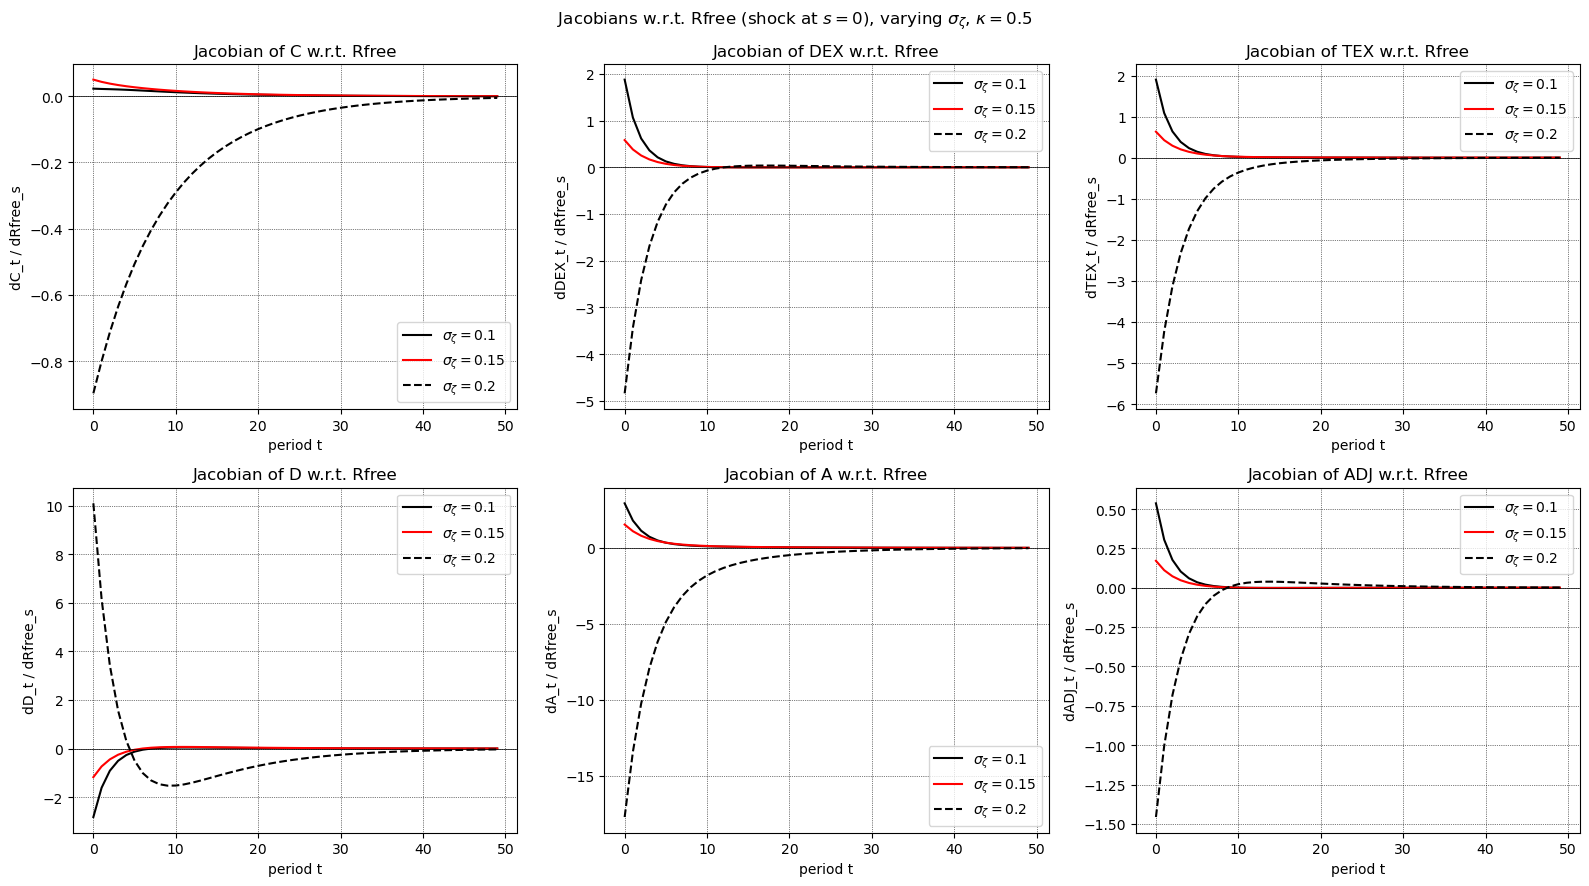

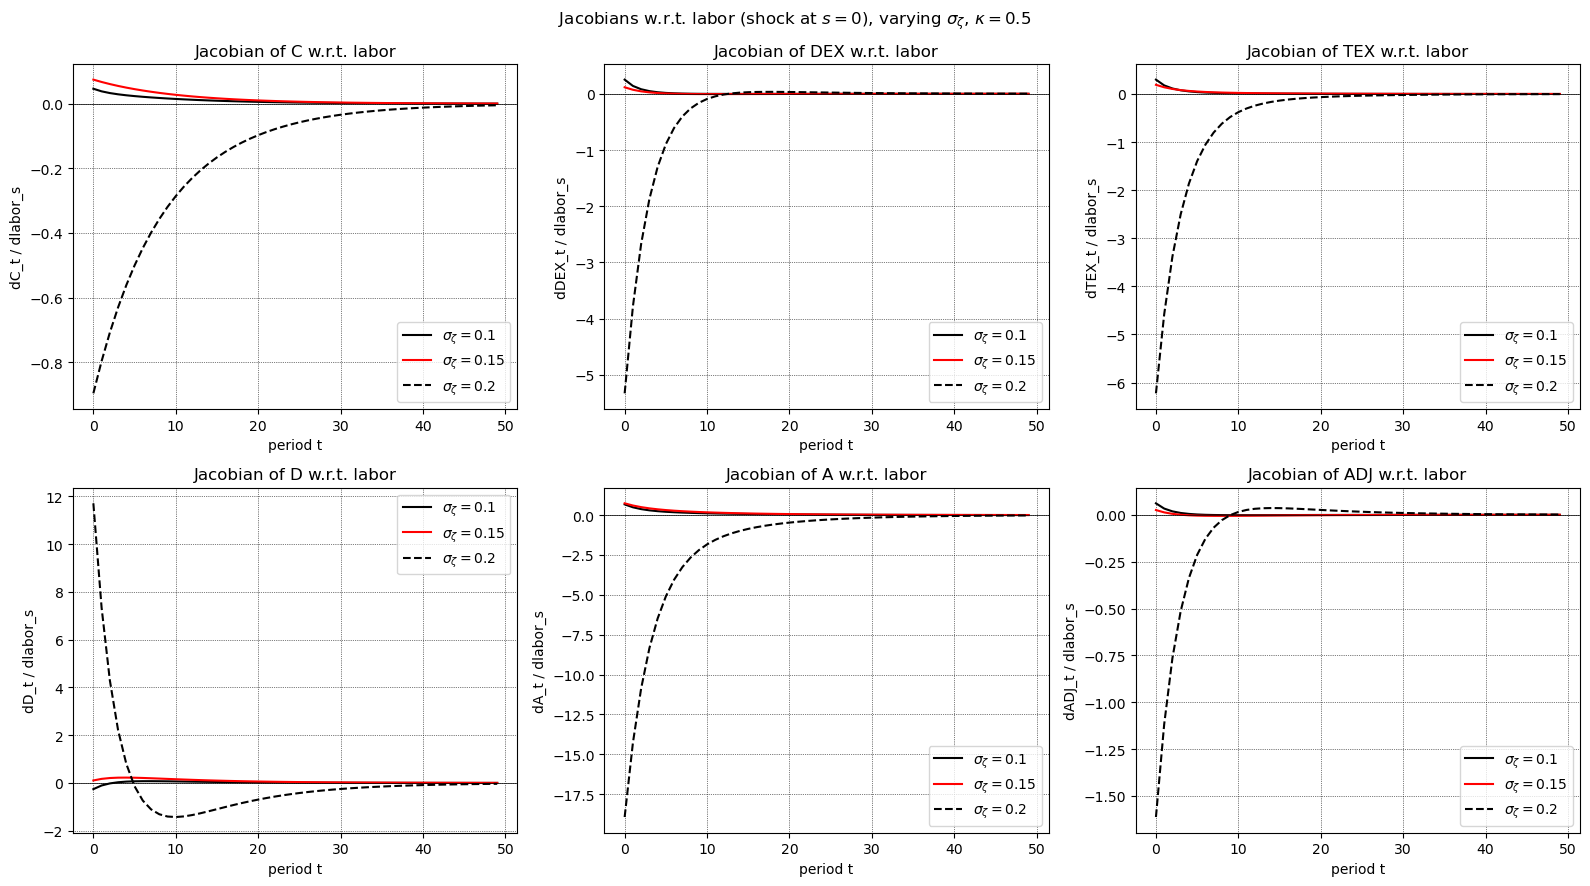

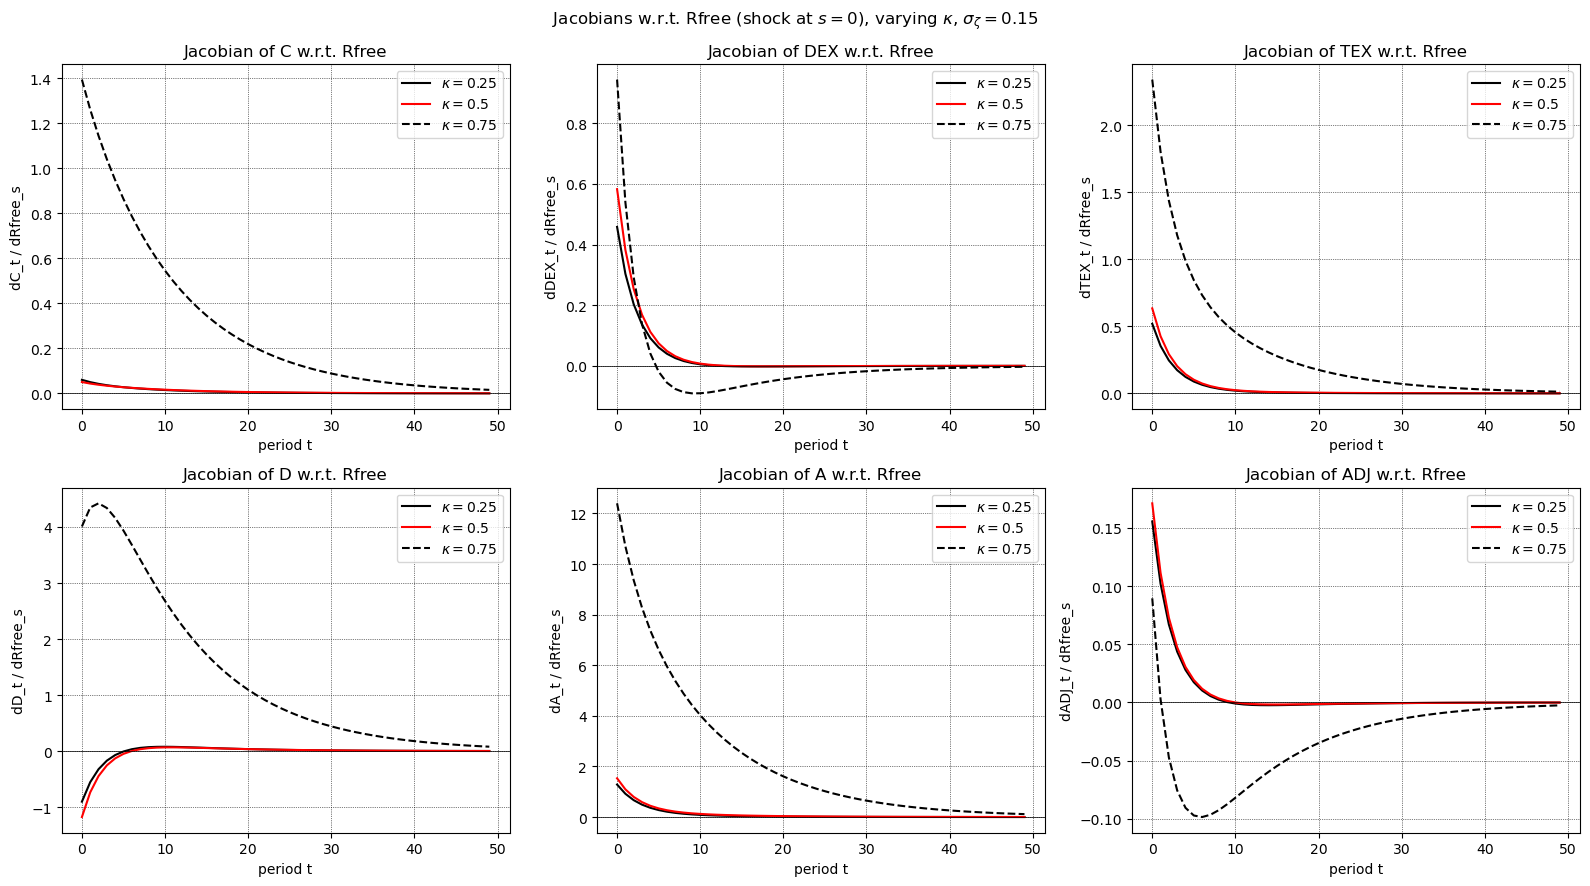

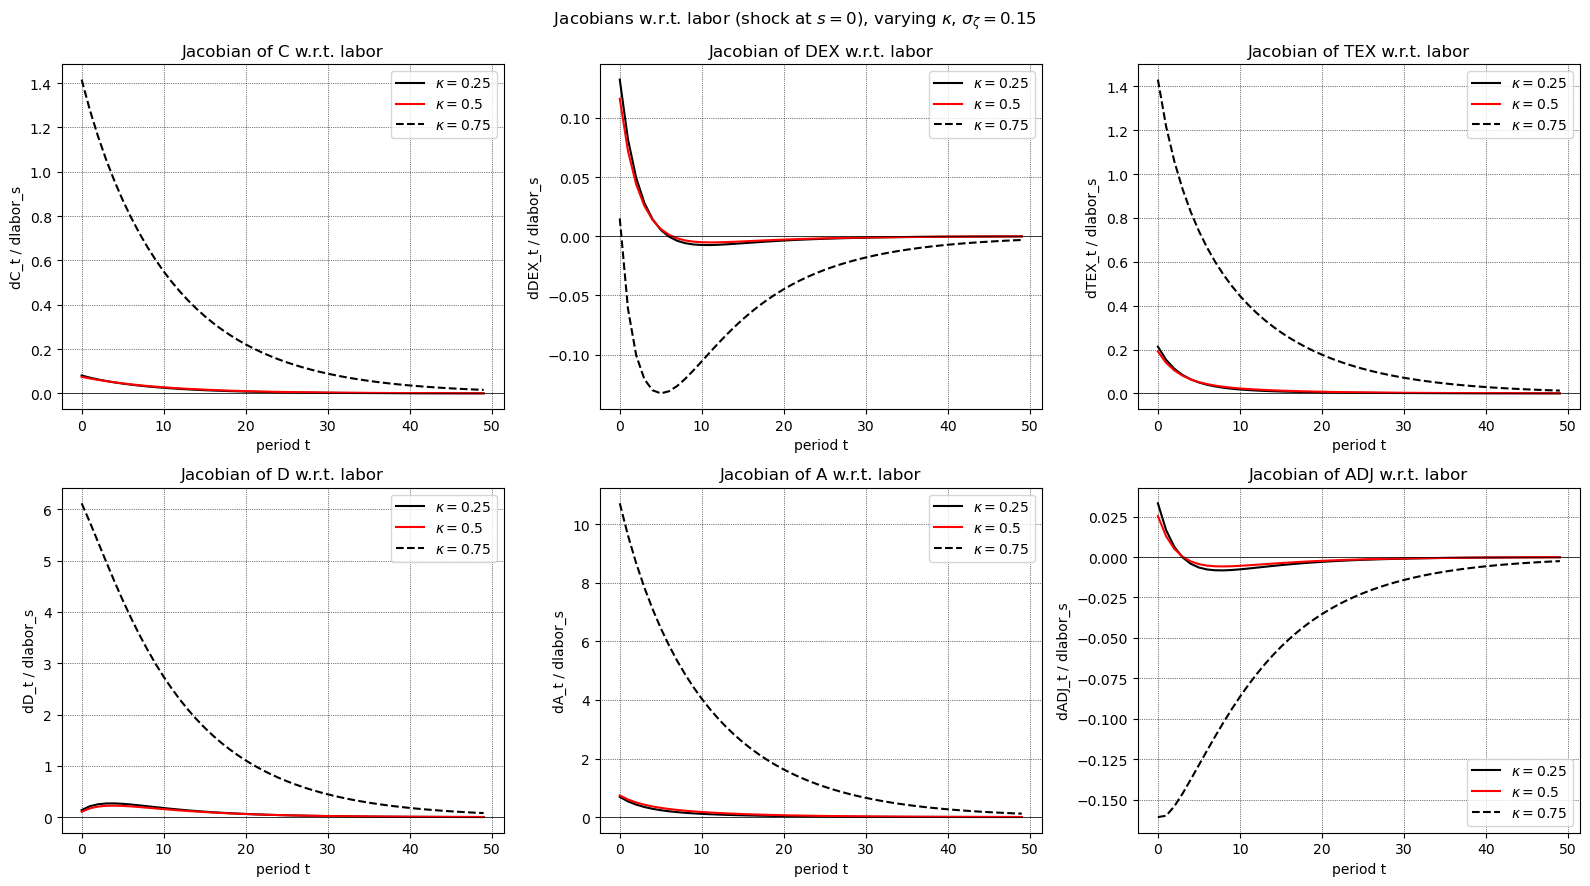

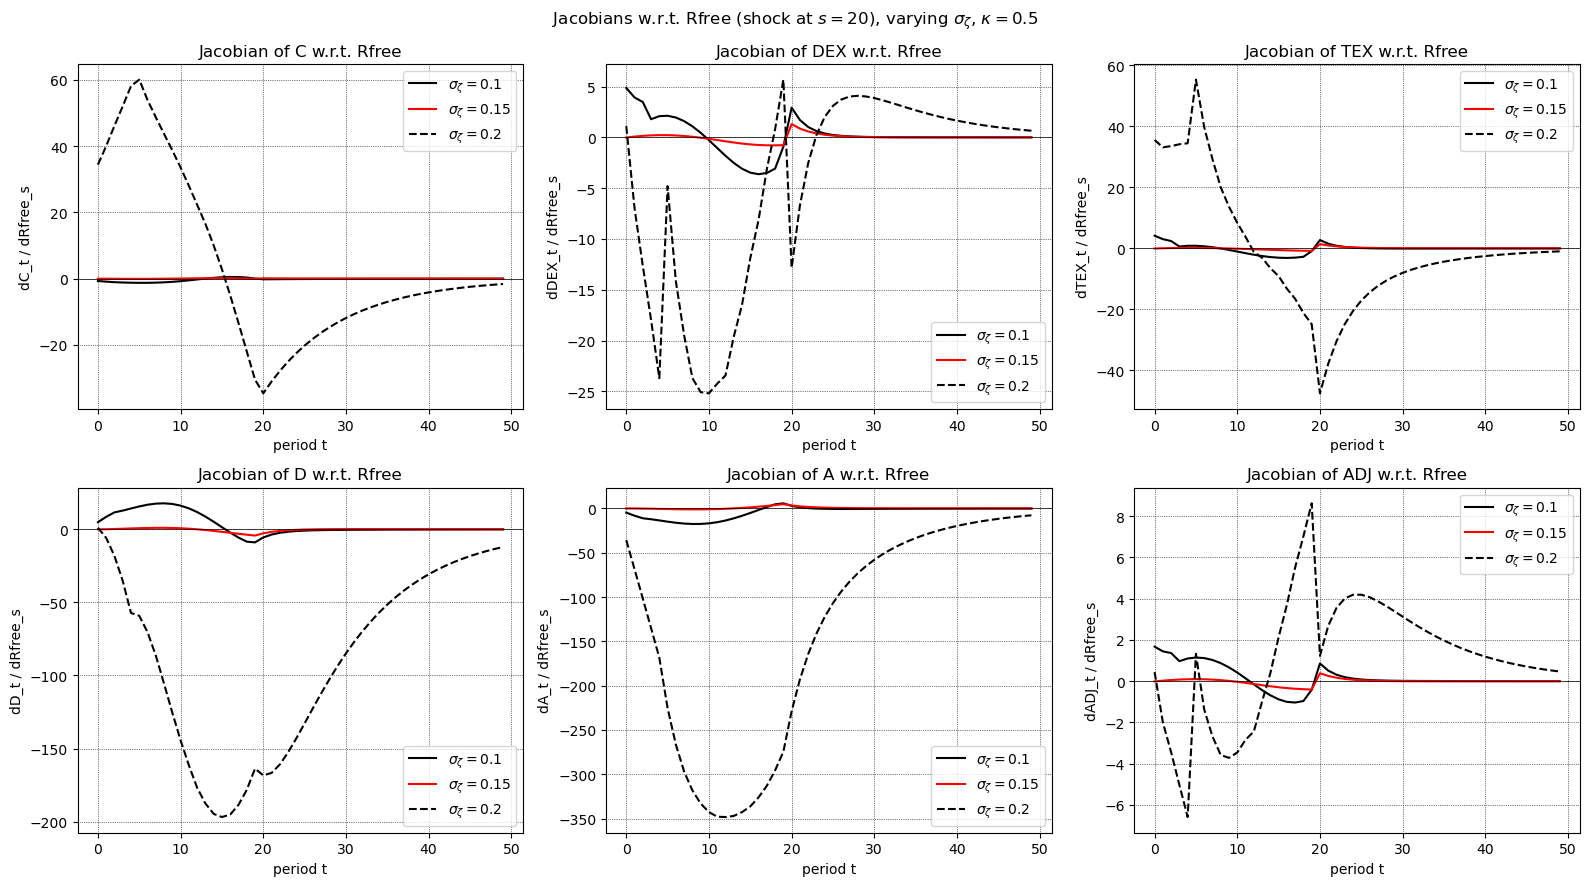

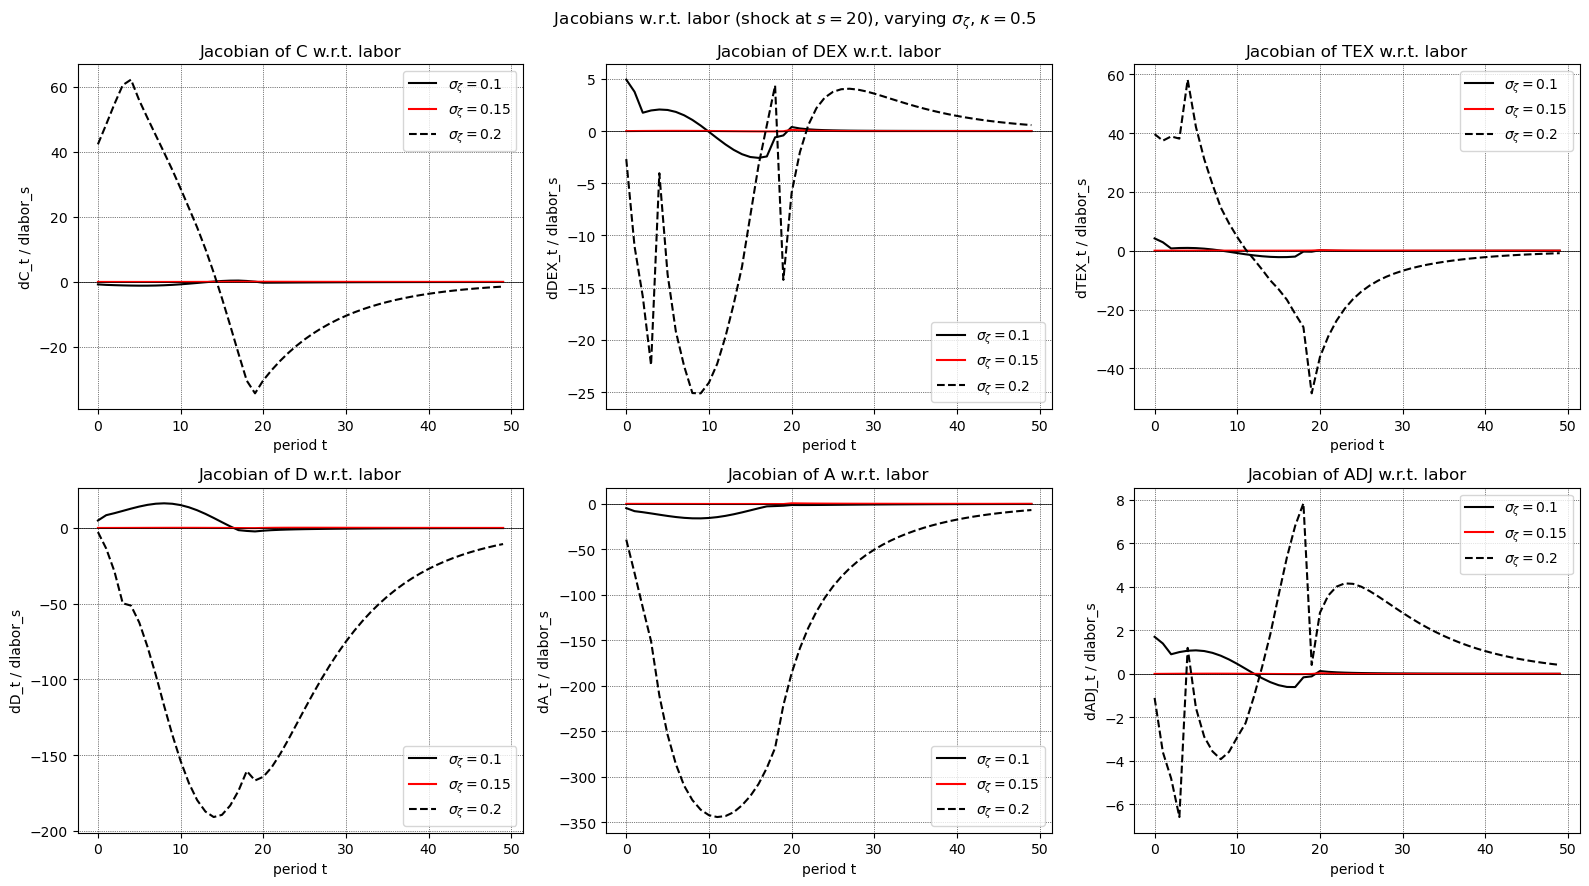

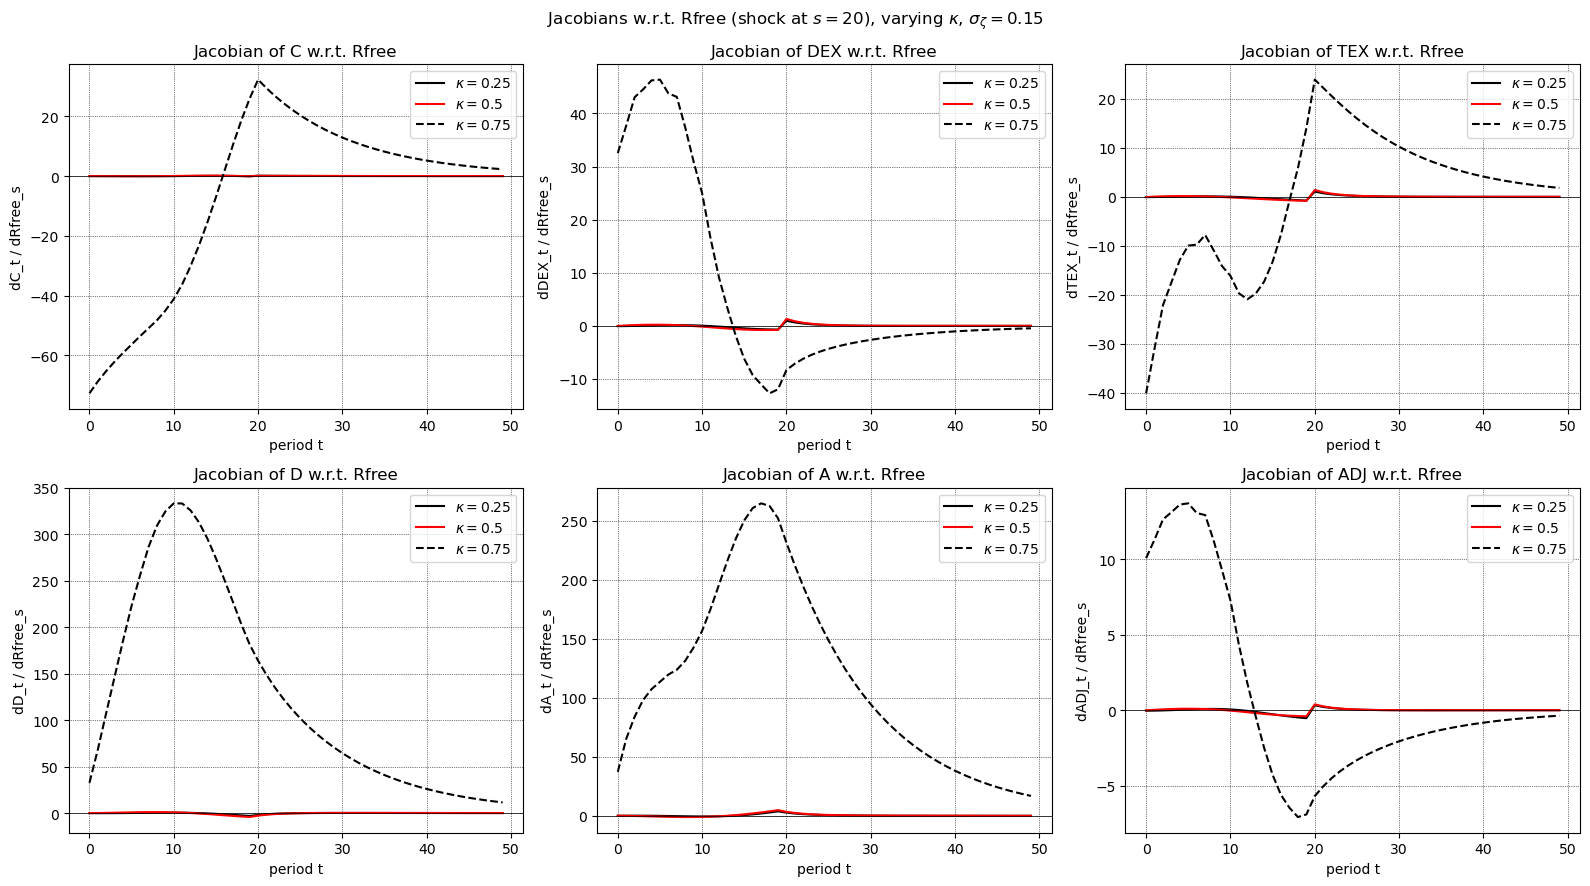

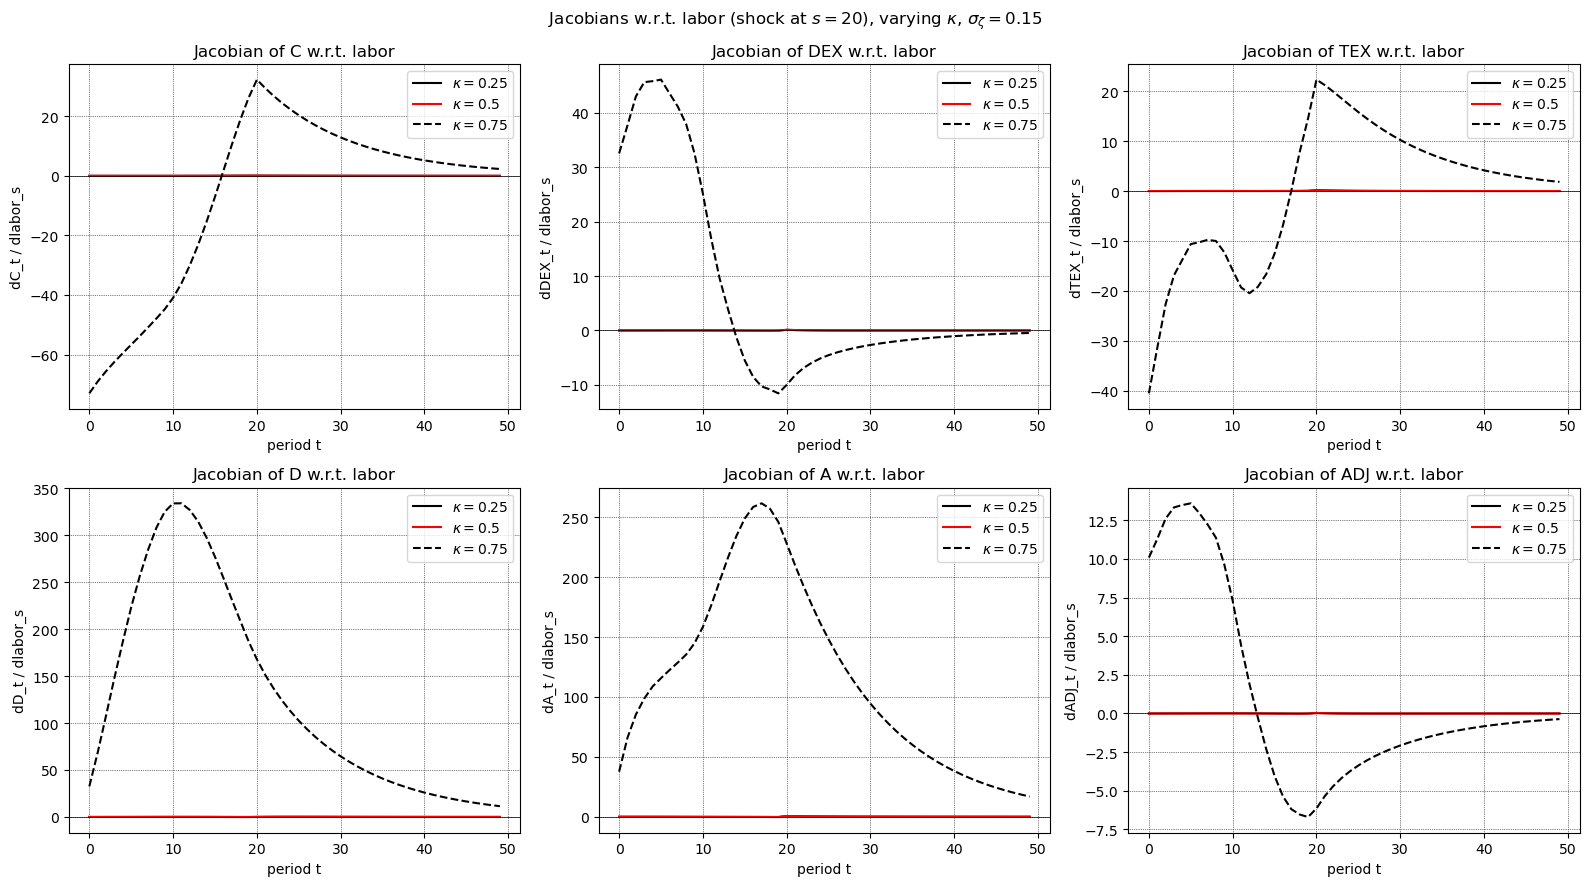

In [6]:
def plot_jacobians(results, shock_name, shock_s, vary_tex, held_tex, stem):
    """Overlay IRFs for one sweep. shock_name is 'Rfree' or 'labor'."""
    key = "jacobians_Rfree" if shock_name == "Rfree" else "jacobians_labor"
    suptitle = (
        rf"Jacobians w.r.t. {shock_name} (shock at $s={shock_s}$), "
        rf"varying {vary_tex}, {held_tex}"
    )
    fig, axes = plt.subplots(2, 3, figsize=(16, 9))
    for ax, name in zip(axes.flat, JAC_KEYS):
        for r, (color, ls) in zip(results, LINE_STYLES):
            J = r[key][name]
            ax.plot(J[:, shock_s], color=color, linestyle=ls, label=r["label"])
        ax.axhline(0.0, color="k", lw=0.5)
        ax.set_title(f"Jacobian of {name} w.r.t. {shock_name}")
        ax.set_xlabel("period t")
        ax.set_ylabel(f"d{name}_t / d{shock_name}_s")
        ax.grid(color="k", linestyle=":", linewidth=0.5)
        ax.legend(loc="best")
    fig.suptitle(suptitle)
    fig.tight_layout()
    path = FIG_DIR / f"{stem}.pdf"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    return path


held_k = rf"$\kappa = {KAPPA_BASE}$"
held_s = rf"$\sigma_{{\zeta}} = {SIGMA_BASE}$"
for shock_s, tag in ((0, ""), (20, "_t20")):
    plot_jacobians(
        results_sigma, "Rfree", shock_s, r"$\sigma_{\zeta}$", held_k,
        f"Taste_kappa_Inf_Jacobians_Rfree_sigma{tag}",
    )
    plot_jacobians(
        results_sigma, "labor", shock_s, r"$\sigma_{\zeta}$", held_k,
        f"Taste_kappa_Inf_Jacobians_labor_sigma{tag}",
    )
    plot_jacobians(
        results_kappa, "Rfree", shock_s, r"$\kappa$", held_s,
        f"Taste_kappa_Inf_Jacobians_Rfree_kappa{tag}",
    )
    plot_jacobians(
        results_kappa, "labor", shock_s, r"$\kappa$", held_s,
        f"Taste_kappa_Inf_Jacobians_labor_kappa{tag}",
    )


In [7]:
def sweep_payload(results, ss_table):
    return {
        "channel": results[0]["channel"],
        "param_name": results[0]["param_name"],
        "param_col": results[0]["param_col"],
        "param_values": [r["param"] for r in results],
        "labels": [r["label"] for r in results],
        "held_name": results[0]["held_name"],
        "held": results[0]["held"],
        "sigma_base": SIGMA_BASE,
        "kappa_base": KAPPA_BASE,
        "steady_states": {r["param"]: r["ss"] for r in results},
        "kink_euler": {r["param"]: r["kink_euler"] for r in results},
        "kink_euler_t": 0,
        "ss_table": ss_table,
    }


def jac_payload(results, shk_param):
    key = "jacobians_Rfree" if shk_param == "Rfree" else "jacobians_labor"
    return {
        "channel": results[0]["channel"],
        "param_name": results[0]["param_name"],
        "param_col": results[0]["param_col"],
        "param_values": [r["param"] for r in results],
        "labels": [r["label"] for r in results],
        "held_name": results[0]["held_name"],
        "held": results[0]["held"],
        "T": T,
        "shk_param": shk_param,
        "jacobians": {r["param"]: r[key] for r in results},
    }


ss_path = OUT_DIR / "DurableModel_Taste_kappa_Inf_SS.pkl"
jac_path_Rfree = OUT_DIR / "DurableModel_Taste_kappa_Inf_Jacobians_Rfree.pkl"
jac_path_labor = OUT_DIR / "DurableModel_Taste_kappa_Inf_Jacobians_labor.pkl"

ss_payload = {
    "sigma_base": SIGMA_BASE,
    "kappa_base": KAPPA_BASE,
    "vary_sigma": sweep_payload(results_sigma, ss_table_sigma),
    "vary_kappa": sweep_payload(results_kappa, ss_table_kappa),
}
jac_payload_Rfree = {
    "sigma_base": SIGMA_BASE,
    "kappa_base": KAPPA_BASE,
    "vary_sigma": jac_payload(results_sigma, "Rfree"),
    "vary_kappa": jac_payload(results_kappa, "Rfree"),
}
jac_payload_labor = {
    "sigma_base": SIGMA_BASE,
    "kappa_base": KAPPA_BASE,
    "vary_sigma": jac_payload(results_sigma, "labor"),
    "vary_kappa": jac_payload(results_kappa, "labor"),
}

with open(ss_path, "wb") as f:
    pickle.dump(ss_payload, f)
with open(jac_path_Rfree, "wb") as f:
    pickle.dump(jac_payload_Rfree, f)
with open(jac_path_labor, "wb") as f:
    pickle.dump(jac_payload_labor, f)

elapsed = time.time() - start_time
print(f"Saved {ss_path.resolve()}")
print(f"Saved {jac_path_Rfree.resolve()}")
print(f"Saved {jac_path_labor.resolve()}")
print("Done in", str(datetime.timedelta(seconds=elapsed)))


Saved C:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Output\DurableModel_Taste_kappa_Inf_SS.pkl
Saved C:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Output\DurableModel_Taste_kappa_Inf_Jacobians_Rfree.pkl
Saved C:\Users\amonninger\OneDrive - Texas A&M University\GitHub\AMonninger\DCEGM_Search\Output\DurableModel_Taste_kappa_Inf_Jacobians_labor.pkl
Done in 0:22:26.227482
